# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [7]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 0.1. Перевіряємо чи ми точно в Colab

In [9]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [10]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі ПІСЛЯ, викликаючи `set_seed()`. Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [11]:
import random

numbers = list(range(10))  # список для shuffle

print("До set_seed() — спроба 1:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

print("\nДо set_seed() — спроба 2:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
print("\nSeed зафіксовано:", SEED)

set_seed()
print("\nПісля set_seed() — спроба 1:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
print("\nПісля set_seed() — спроба 2:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

До set_seed() — спроба 1:
randint: 89
shuffle: [6, 0, 1, 7, 2, 8, 9, 4, 3, 5]

До set_seed() — спроба 2:
randint: 4
shuffle: [2, 7, 5, 9, 1, 8, 4, 3, 6, 0]

Seed зафіксовано: 42

Після set_seed() — спроба 1:
randint: 82
shuffle: [3, 9, 5, 6, 8, 4, 0, 1, 2, 7]

Після set_seed() — спроба 2:
randint: 82
shuffle: [1, 6, 5, 2, 4, 0, 7, 8, 3, 9]


# Що відбувається після set_seed()?

Генератор псевдовипадкових чисел у Python обчислює наступне число за формулою на основі внутрішнього стану. Коли не задаємо seed, цей стан ініціалізується чимось непередбачуваним (наприклад, поточним часом) — тому кожен запуск randint() або shuffle() дає інший результат.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [12]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [13]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [15]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [16]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print("identity.ndim:", identity.ndim)
print("random_ints.ndim:", random_ints.ndim)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
identity.ndim: 2
random_ints.ndim: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [17]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [18]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [19]:
df = pd.DataFrame({
    "name": ["Olga", "Ivan", "Maria", "Petro", "Natalia", "Andriy"],
    "score": [78, 85, 92, 67, 90, 74]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


      name  score
2    Maria     92
4  Natalia     90
1     Ivan     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [20]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
conditions = [
    df["score"] >= 90,
    df["score"] >= 75
]
choices = ["A", "B"]
df["grade"] = np.select(conditions, choices, default="C")
print(df)


      name  score grade
0     Olga     78     B
1     Ivan     85     B
2    Maria     92     A
3    Petro     67     C
4  Natalia     90     A
5   Andriy     74     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [21]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print(sevens_t)


tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [22]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [23]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(random_t)
print("\nfrom_list  -> shape:", from_list.shape, " dtype:", from_list.dtype, " ndim:", from_list.ndim)
print("random_t   -> shape:", random_t.shape, " dtype:", random_t.dtype, " ndim:", random_t.ndim)


tensor([[1, 2],
        [3, 4]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])

from_list  -> shape: torch.Size([2, 2])  dtype: torch.int64  ndim: 2
random_t   -> shape: torch.Size([3, 3])  dtype: torch.float32  ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [24]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
print("x.grad.item() =", x.grad.item())
print("2n =", 2 * n)
print("Збігається:", torch.isclose(torch.tensor(x.grad.item()), torch.tensor(2 * n)))

x.grad.item() = 10.0
2n = 10.0
Збігається: tensor(True)


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [25]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()
for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()
    print(f"крок {step+1:2d}: x = {x.item():.4f}, loss = {loss.item():.4f}")
print(f"x = {x.item():.4f}  (мінімум у x=3)")


крок  1: x = 0.6000, loss = 14.0000
крок  2: x = 1.0800, loss = 10.7600
крок  3: x = 1.4640, loss = 8.6864
крок  4: x = 1.7712, loss = 7.3593
крок  5: x = 2.0170, loss = 6.5099
крок  6: x = 2.2136, loss = 5.9664
крок  7: x = 2.3709, loss = 5.6185
крок  8: x = 2.4967, loss = 5.3958
крок  9: x = 2.5973, loss = 5.2533
крок 10: x = 2.6779, loss = 5.1621
крок 11: x = 2.7423, loss = 5.1038
крок 12: x = 2.7938, loss = 5.0664
крок 13: x = 2.8351, loss = 5.0425
крок 14: x = 2.8681, loss = 5.0272
крок 15: x = 2.8944, loss = 5.0174
крок 16: x = 2.9156, loss = 5.0111
крок 17: x = 2.9324, loss = 5.0071
крок 18: x = 2.9460, loss = 5.0046
крок 19: x = 2.9568, loss = 5.0029
крок 20: x = 2.9654, loss = 5.0019
x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

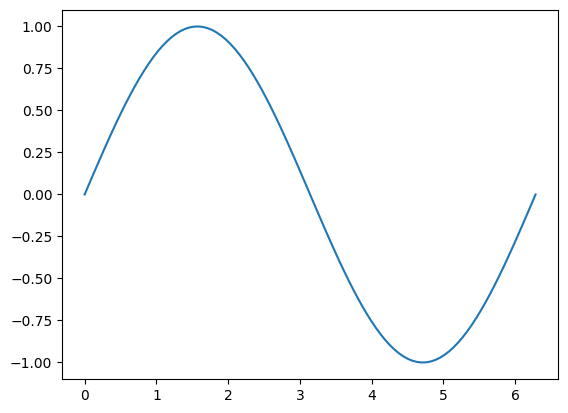

In [26]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

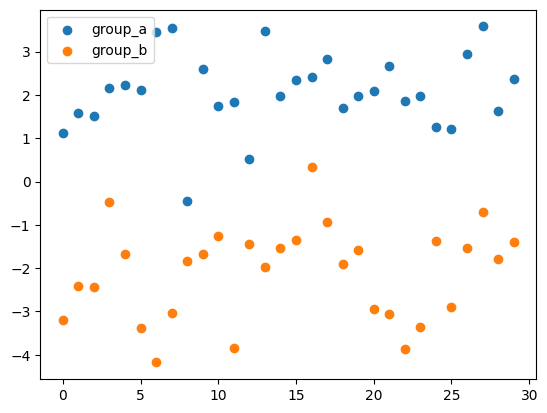

In [27]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()
plt.scatter(np.arange(30), group_a, color="C0", label="group_a")
plt.scatter(np.arange(30), group_b, color="C1", label="group_b")
plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [28]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

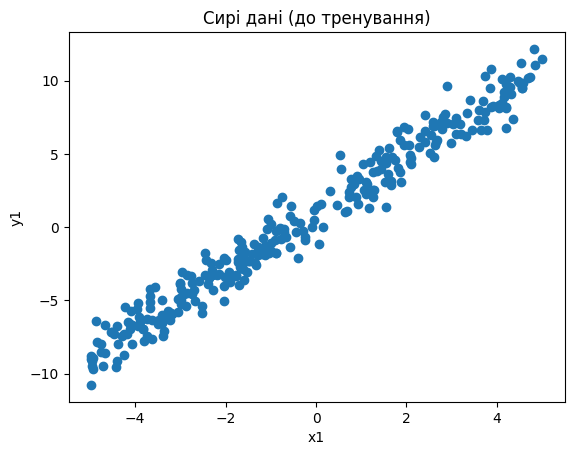

In [29]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1, y1)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [30]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...
perm = torch.randperm(TASK1_N)
n_train = int(0.7 * TASK1_N)
n_val = int(0.15 * TASK1_N)
train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]
x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]
print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [31]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


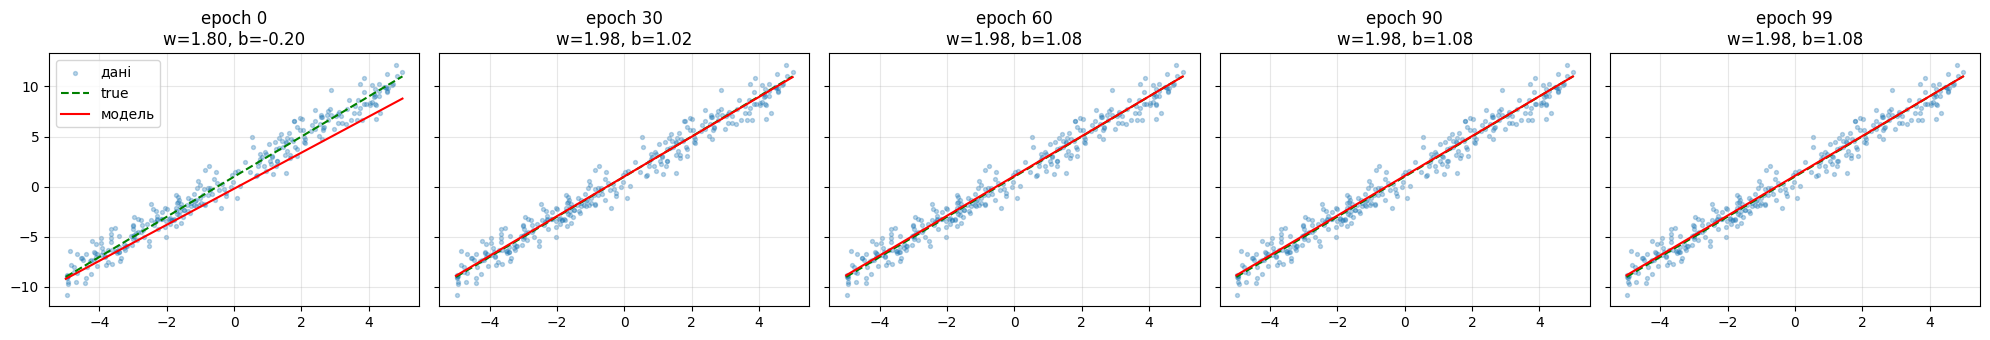

In [32]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

Залежність: кількість чашок кави, випитих за день (`x`) → час, потрібний, щоб заснути ввечері, тобто затримка засинання у хвилинах (`y`).

Значення:

- w = 18.0 — кожна додаткова чашка кави в середньому додає ~18 хвилин до часу засинання. Кофеїн блокує аденозинові рецептори, і його ефект накопичується; в дослідженнях сну зустрічаються оцінки приблизно 10–20 хв затримки на одну порцію кофеїну, тож взяв середнє з цього діапазону.
- b = 15.0 — базовий час засинання без кави (~15 хв), що відповідає нормальному часу засинання здорової дорослої людини.
- шум ε ~ N(0, 10) — хвилини коливаються через стрес, звичку до кофеїну, час доби вживання кави тощо. Стандартне відхилення 10 хв обрано так, щоб шум був помітним.
- діапазон x: 0–6 чашок на день — реалістичний діапазон споживання кави звичайною людиною.

Значення y після додавання шуму обрізаю знизу нулем (`clip`), бо від'ємна затримка засинання фізично неможлива.

Збережено 200 рядків у dataset.csv


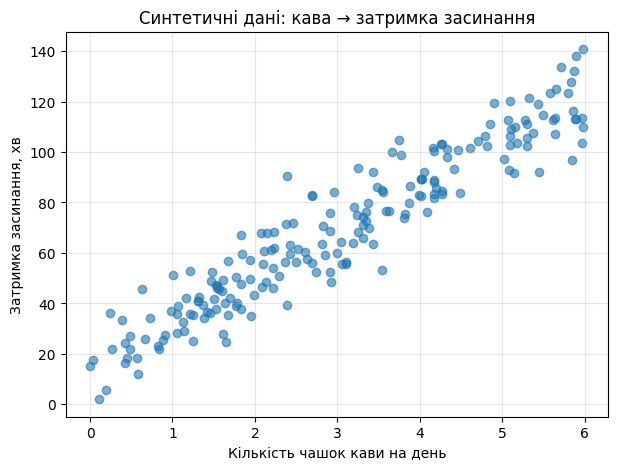

Epoch 0: loss=5869.6982
Epoch 25: loss=107.8570
Epoch 50: loss=103.2643
Epoch 75: loss=101.7645
Epoch 100: loss=101.2748
Epoch 125: loss=101.1149
Epoch 150: loss=101.0626
Epoch 175: loss=101.0456
Знайдені: w=17.9384, b=15.2478
Справжні: w=18.0, b=15.0
MSE на test: 79.7291


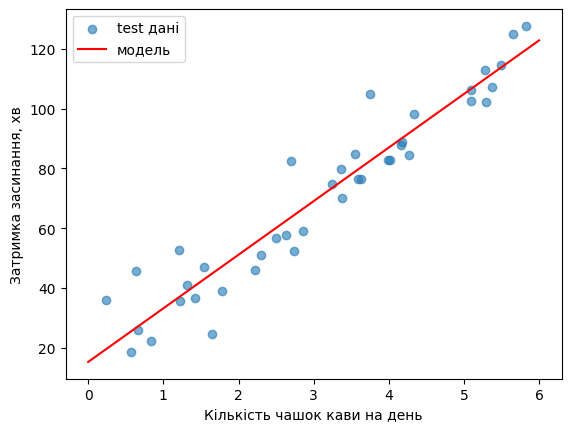

In [33]:
w_true = 18.0
b_true = 15.0
noise_std = 10.0
n_samples = 200

X = np.random.uniform(0, 6, n_samples)
noise = np.random.normal(0, noise_std, n_samples)
y = w_true * X + b_true + noise
y = np.clip(y, 0, None)
df = pd.DataFrame({
    "coffee_cups": X,
    "sleep_delay_min": y
})
csv_path = "dataset.csv"
df.to_csv(csv_path, index=False)
print(f"Збережено {len(df)} рядків у {csv_path}")
plt.figure(figsize=(7, 5))
plt.scatter(df["coffee_cups"], df["sleep_delay_min"], alpha=0.6)
plt.xlabel("Кількість чашок кави на день")
plt.ylabel("Затримка засинання, хв")
plt.title("Синтетичні дані: кава → затримка засинання")
plt.grid(alpha=0.3)
plt.show()

def load_data(path):
    data = pd.read_csv(path)
    X = data["coffee_cups"].values.astype("float32").reshape(-1, 1)
    y = data["sleep_delay_min"].values.astype("float32").reshape(-1, 1)
    return torch.tensor(X), torch.tensor(y)

def split_data(X, y, test_ratio=0.2):
    n_test = int(test_ratio * len(X))
    return X[n_test:], y[n_test:], X[:n_test], y[:n_test]

def train_linear_regression(X_train, y_train, lr=0.05, epochs=200):
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(X_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()
        if epoch % 25 == 0:
            print(f"Epoch {epoch}: loss={loss.item():.4f}")
    return model

def evaluate(model, X_test, y_test):
    loss_fn = torch.nn.MSELoss()
    with torch.no_grad():
        return loss_fn(model(X_test), y_test).item()

X, y = load_data(csv_path)
X_train, y_train, X_test, y_test = split_data(X, y, test_ratio=0.2)
model = train_linear_regression(X_train, y_train, lr=0.05, epochs=200)
w, b = model.weight.item(), model.bias.item()
print(f"Знайдені: w={w:.4f}, b={b:.4f}")
print(f"Справжні: w={w_true}, b={b_true}")
test_loss = evaluate(model, X_test, y_test)
print(f"MSE на test: {test_loss:.4f}")
plt.scatter(X_test, y_test, alpha=0.6, label="test дані")
x_line = np.linspace(0, 6, 100).astype("float32").reshape(-1, 1)
with torch.no_grad():
    y_line = model(torch.tensor(x_line)).numpy()
plt.plot(x_line, y_line, color="red", label="модель")
plt.xlabel("Кількість чашок кави на день")
plt.ylabel("Затримка засинання, хв")
plt.legend()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [37]:
torch.save(model.state_dict(), "/content/drive/MyDrive/model.pt")
print("Модель збережено")

Модель збережено


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [35]:
!pip install -q gradio
import gradio as gr

In [36]:
loaded_model = torch.nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load("/content/drive/MyDrive/model.pt"))
loaded_model.eval()

def predict_sleep_delay(coffee_cups):
    x_input = torch.tensor([[coffee_cups]], dtype=torch.float32)
    with torch.no_grad():
        prediction = loaded_model(x_input)
    return round(prediction.item(), 2)

demo = gr.Interface(
    fn=predict_sleep_delay,
    inputs=gr.Number(label="Кількість чашок кави на день", value=2),
    outputs=gr.Number(label="Прогнозована затримка засинання, хв"),
    title="Прогноз затримки засинання за кількістю кави",
    description="Лінійна регресія: y = w·x + b, натренована на синтетичних даних"
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://deb1532fd718508a38.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```